# Prédire les durées de trajet à Casablanca

Le générateur associe à chaque arc dirigé la distance et la durée statique OSRM $s$. Il simule $y=s\max(0{,}8,M)$, où $M$ additionne une contribution de pointe selon le type de jour, des effets de zone, un bruit gaussien et un choc d'incident. Les données routières proviennent du réseau OpenStreetMap. Les valeurs $y$ sont simulées.

On compare l'estimation directe $\hat y=f(x)$ à l'estimation d'un facteur $g(x)$ suivie de $\hat y=s\,g(x)$. La régression minimise les carrés dans l'espace de sa cible. Un résidu de $0{,}1$ sur le ratio représente 1 min si $s=10$ min et 2 min si $s=20$ min. En minutes, les grands trajets pèsent donc davantage dans les carrés. Toutes les méthodes sont finalement comparées par MAE en minutes.

Les cycles utilisent $\sin(2\pi t/P)$ et $\cos(2\pi t/P)$ pour préserver la proximité aux frontières. Distances, durée de référence, calendrier, zones et relation intra/interzone sont disponibles à l'heure de départ. Le simulateur tire l'incident avec la réalisation du trajet. Le label d'incident et les durées réalisées ne figurent jamais dans les prédicteurs. Les statistiques historiques, les catégories et les transformations sont estimées sur l'entraînement.

[Source géographique © OpenStreetMap contributors](https://www.openstreetmap.org/copyright) · [Données routières publiques candidates de Rouky et Bousouf, 2023](https://data.mendeley.com/datasets/8hj76bpzpv/1)

In [1]:
import json
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

root = Path.cwd()
if not (root / "configs/traffic_ml.yaml").is_file():
    root = root.parent
sys.path.insert(0, str(root))
from src.ml.features import INPUTS, chronological_split, make_features

results = root / "results/experiments/traffic_ml"
manifest = json.loads((results / "manifest.json").read_text())
config = manifest["config"]
display(pd.DataFrame(manifest["partitions"]).T)
print(f"Référence : {manifest['reference_checkpoint']}. Modèle choisi sur validation : {manifest['selected']}.")

Référence : 108d2fd. Modèle choisi sur validation : linear/ratio/ols.


,start,end,rows,days
train,2026-04-06,2026-05-09,6095,34
validation,2026-05-10,2026-05-20,1939,11
test,2026-05-21,2026-05-31,1966,11


## Comparaison et protocole

La baseline statique prédit $s$. La baseline historique prédit $s$ multiplié par le ratio moyen d'entraînement pour l'heure et le type de jour. La régression estime des contributions additives. La forêt agrège des arbres ajustés sur des rééchantillons. XGBoost et LightGBM construisent des arbres successifs qui améliorent une prédiction précédente. Deux réglages par famille d'arbres et par cible ont été testés sur la validation. Les meilleurs réglages et le modèle à sauvegarder sont figés avant de calculer le test.

La MAE et la RMSE sont en minutes. Le biais est la moyenne de la prédiction moins la durée simulée. Le $R^2$ compare les erreurs quadratiques à celles d'une prédiction constante. L'inférence chronomètre un lot de 1 966 lignes, avec une médiane de cinq appels après échauffement et sans lecture du disque.

In [2]:
validation = pd.read_csv(results / "validation_finalists.csv").set_index("model")
test = pd.read_csv(results / "test_metrics.csv").set_index("model")
display(test.join(validation[["mae"]].rename(columns={"mae": "validation_mae"}))
        .sort_values("mae").round(4))
display(pd.read_csv(results / "ablations.csv").round(4))

,mae,rmse,r2,bias,batch_ms,rows,validation_mae
model,,,,,,,
linear/ratio/ols,1.2882,2.1760,0.9326,-0.0591,28.5928,1966,1.2594
xgboost/ratio/depth_2,1.2910,2.1818,0.9322,-0.0467,32.5240,1966,1.2607
random_forest/ratio/depth_5,1.2954,2.1895,0.9317,-0.0459,111.8422,1966,1.2620
lightgbm/ratio/leaves_7,1.2965,2.1947,0.9314,-0.0510,34.9411,1966,1.2694
lightgbm/absolute/leaves_7,1.3228,2.2148,0.9301,-0.0593,40.5519,1966,1.3067
xgboost/absolute/depth_2,1.3532,2.2240,0.9296,-0.0545,63.8512,1966,1.3182
random_forest/absolute/depth_10,1.3587,2.2611,0.9272,-0.0349,109.2531,1966,1.3478
historical_average,1.4104,2.2938,0.9251,0.0504,21.6885,1966,1.4001
linear/absolute/ols,1.6761,2.4917,0.9116,-0.0284,44.9037,1966,1.6901


,model,partition,mae,rmse,r2,bias
0,static_and_distance_only,validation,2.3830,3.3876,0.8378,0.1421
1,static_and_distance_only,test,2.3074,3.3114,0.8438,0.0902
2,without_generator_flags,validation,2.1777,3.1780,0.8573,0.1302
3,without_generator_flags,test,2.1087,3.1117,0.8621,-0.0543


Le ratio améliore la MAE de chaque famille par rapport à sa version absolue sur les journées de test. La structure multiplicative du générateur avantage cette représentation. Le $R^2$ demeure élevé avec la seule géométrie, alors que la MAE se dégrade fortement. Une bonne prédiction du niveau de durée ne suffit donc pas à établir une bonne estimation de la congestion. L'ablation des indicateurs explicitement inspirés du générateur réduit fortement la performance linéaire. Des variables restantes peuvent encore coder des informations corrélées, et cette ablation ne mesure pas une causalité.

,dimension,group,n,mae,rmse,r2,bias
0,intensity,low,913,1.106,1.568,0.945,0.841
1,intensity,medium,625,1.099,1.559,0.962,-0.365
2,intensity,high,428,1.953,3.599,0.886,-1.532
3,hour,6,131,1.562,2.306,0.902,0.127
4,hour,7,114,1.333,2.341,0.939,-0.313
5,hour,8,117,1.087,2.159,0.946,-0.017
6,hour,9,141,1.283,1.911,0.958,0.022
7,hour,10,116,1.057,1.794,0.925,-0.117
8,hour,11,103,1.444,2.571,0.883,-0.486
9,hour,12,125,1.615,2.704,0.871,0.152


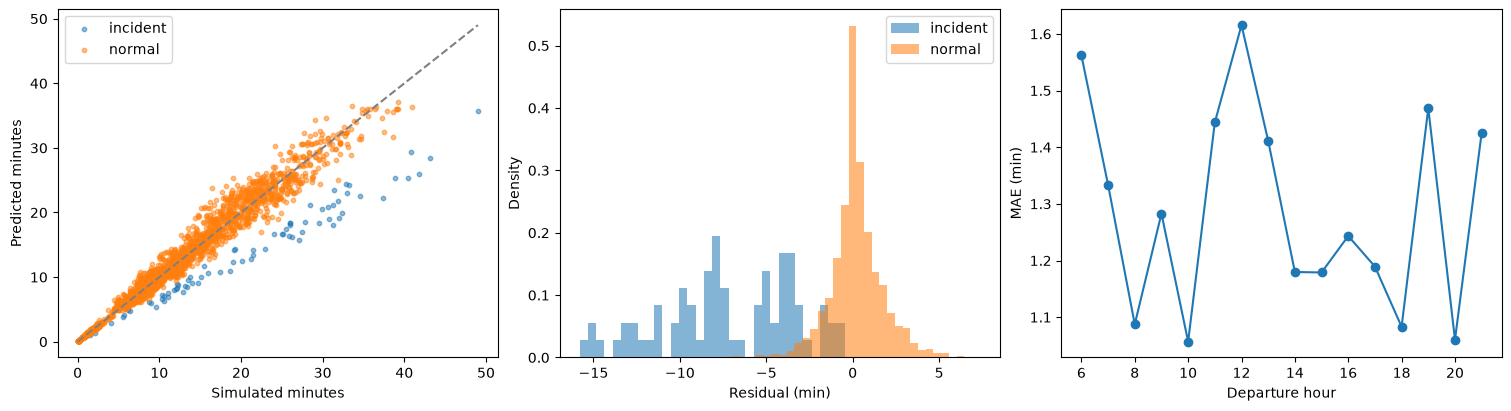

In [3]:
residuals = pd.read_csv(results / "test_residuals.csv")
strata = pd.read_csv(results / "test_strata.csv")
display(strata.round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for group, rows in residuals.groupby("incident"):
    axes[0].scatter(rows.actual_simulated_min, rows.predicted_min, label=group, s=10, alpha=.5)
    axes[1].hist(rows.residual_min, bins=32, label=group, alpha=.55, density=True)
limit = residuals.actual_simulated_min.max()
axes[0].plot([0, limit], [0, limit], "--", color="gray")
axes[0].set(xlabel="Simulated minutes", ylabel="Predicted minutes")
axes[0].legend()
axes[1].set(xlabel="Residual (min)", ylabel="Density")
axes[1].legend()
hour = strata[strata.dimension.eq("hour")]
axes[2].plot(hour.group.astype(int), hour.mae, marker="o")
axes[2].set(xlabel="Departure hour", ylabel="MAE (min)")
plt.show()

Les incidents sont fortement sous-estimés et les trajets longs accumulent plus d'erreur en minutes. Les groupes d'intensité sont construits a posteriori avec le ratio réalisé, aux seuils 1,2 et 1,5. Les groupes de distance utilisent les seuils 3 et 8 km. Les effectifs et le biais par groupe rendent visibles les erreurs masquées par la moyenne.

Trajet expliqué : C03 → C18.
Sortie dans l’espace cible : 1.334.
Prévision finale : 19.01 min.


,feature,mae_increase,repeat_sd
1,static_travel_time,7.5905,0.1161
9,weekday_rush,0.8692,0.0315
8,rush,0.3196,0.0089
10,central_zone,0.2534,0.0163
13,road_characteristics,0.0426,0.0010
0,road_distance,0.0148,0.0029
2,hour,0.0102,0.0022
3,hour_sin,0.0077,0.0014


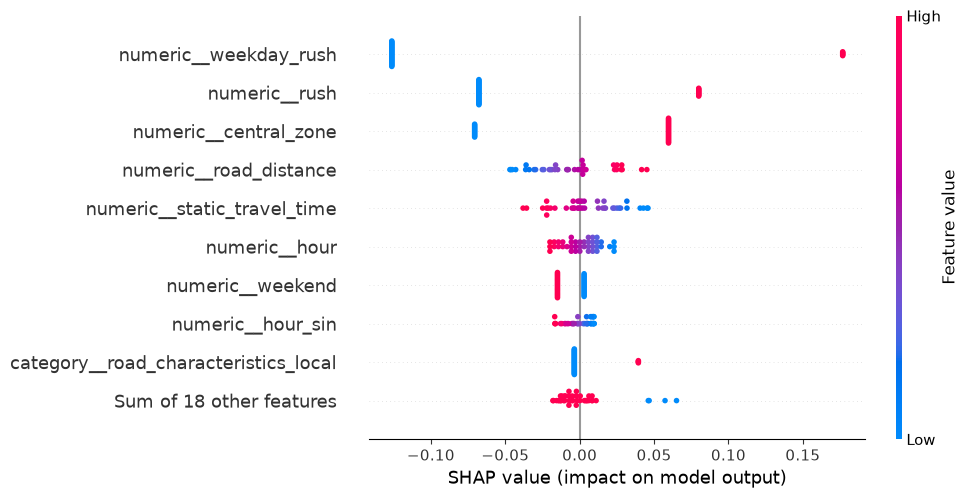

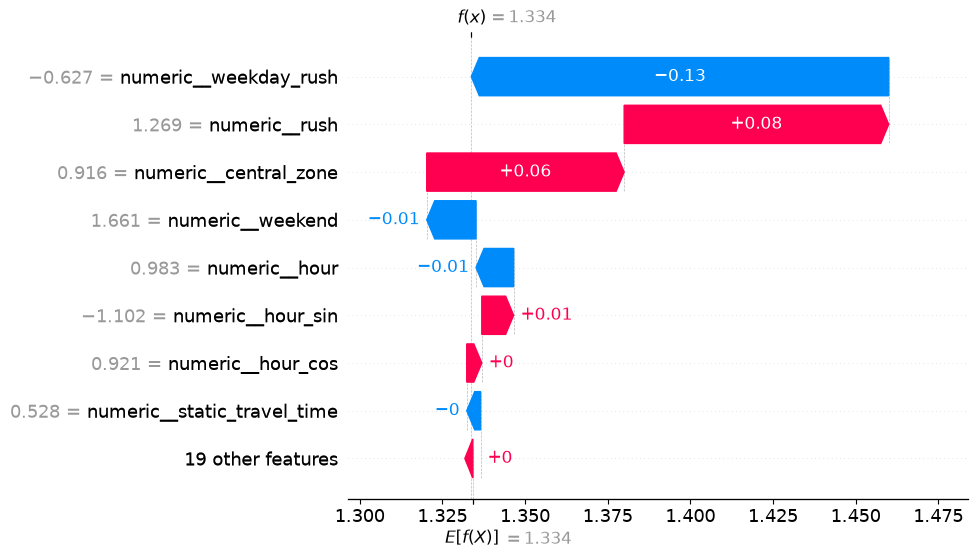

In [4]:
importance = pd.read_csv(results / "permutation_importance.csv").sort_values("mae_increase", ascending=False)
display(importance.head(8).round(4))
bundle = joblib.load(root / "models/traffic_model.joblib")
traffic = pd.read_csv(root / "data/synthetic/traffic_observations.csv")
parts = chronological_split(traffic, config["training_days"], config["validation_days"])
preprocess = bundle.pipeline["preprocess"]
regressor = bundle.pipeline["regressor"]
background = preprocess.transform(make_features(parts["train"].sample(
    config["shap_background"], random_state=config["seed"]), bundle.zones))
sample = parts["test"].sample(config["shap_examples"], random_state=config["seed"])
examples = preprocess.transform(make_features(sample, bundle.zones))
def target_prediction(values):
    return regressor.predict(pd.DataFrame(values, columns=background.columns))

explainer = shap.Explainer(target_prediction, background, algorithm="permutation",
                           seed=config["seed"], feature_names=background.columns.tolist())
attributions = explainer(examples, max_evals=4 * (2 * examples.shape[1] + 1), silent=True)
np.testing.assert_allclose(attributions.base_values + attributions.values.sum(axis=1),
                           target_prediction(examples), rtol=1e-6, atol=1e-7)
shap.plots.beeswarm(attributions, max_display=10, show=False)
plt.show()
shap.plots.waterfall(attributions[0], max_display=9, show=False)
plt.show()
position = 0
print(f"Trajet expliqué : {sample.iloc[position].origin_id} → {sample.iloc[position].destination_id}.")
print(f"Sortie dans l’espace cible : {target_prediction(examples)[position]:.3f}.")
print(f"Prévision finale : {bundle.predict(sample.loc[:, list(INPUTS)])[position]:.2f} min.")

La permutation estime la perte de précision en minutes sur la validation, y compris lorsque la durée OSRM est perturbée dans la remise à l'échelle du ratio. Les SHAP expliquent la sortie du régresseur dans son espace cible, ici le ratio. Ils utilisent 24 références d'entraînement et 40 exemples du test. Les variables corrélées peuvent se partager les attributions. La sélection, l'entraînement et la vérification de sauvegarde sont reproductibles avec `python -m src.ml.experiment`.

**Portée.** Le test couvre des jours simulés inédits du même générateur et du même réseau. Le jeu Waze public décrit une semaine et un ensemble de trajets distinct. Il demeure une piste de validation externe qui demanderait un appariement des arcs et des périodes. Les métriques de cette expérience n'établissent pas la précision prédictive en circulation réelle.